In [1]:
import sys
sys.path.append("/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts")
import os
import sys
import yaml
import numpy as np
from pathlib import Path
import re
import numpy as np
import netCDF4 as nc
import yaml
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, fixed
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_bout_midplane_distances
from converged_profile_functions import unbiased_convergence, end_biased_convergence

DEFAULT_CONFIG_PATH = "SIBIL_config.yaml"

config_path = DEFAULT_CONFIG_PATH

if not os.path.exists(config_path):
    print(f"Error: config file not found: {config_path}")
    sys.exit(1)

config = load_config(config_path)
sibil_config_summary(config)

# if not confirm():
#     print("Aborted. No changes made.")
#     sys.exit(0)

import sibil  # imported here so summary/confirmation works without dependency installed

INPUT_FILE  = f"{config["base_path"]}/{config["iteration"]}_iteration/b2.transport.inputfile"
OUTPUT_FILE = f"{config["base_path"]}/{int(config["iteration"])+1}_iteration/b2.transport.inputfile"
bout_dir  = Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bout_dir"]}")
data_dir  = bout_dir / "numpy"
grid_fname= Path(f"{config["base_path"]}/{config["iteration"]}_iteration/{config["files"]["bgrid"]}")
grid_fname = str(grid_fname)
transport_coeffs = config["bout_to_solps_pass"]["passed_coeffs"]
profile_sample_timestep = config["bout_to_solps_pass"]["profile_sample_timestep"]
jomp = config["bout_to_solps_pass"]["jomp"]
N, l = config["bout_to_solps_pass"]["N"], config["bout_to_solps_pass"]["l"]

grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

psin = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

sepx_dists_solps = extract_tdata_first_index(INPUT_FILE)
psin_mid, sepx_dists_bout = get_bout_midplane_distances(grid_fname)

convergent_transport_coeffs = {}
interplted_transport_coeffs = {}
# "ddr_Tetot_txy", "ddr_Titot_txy", 
#                                        "ddr_nitot_txy", 
transport_coeffs = transport_coeffs + [#"Vr_t",
                                       "ddr_Tetot_txy", "ddr_Titot_txy", 
                                       "ddr_nitot_txy", 
                                       #"Vexbx_txy", "Vbtildx_txy"
]
for var_name in transport_coeffs:
    var = np.load(f"{data_dir}/{var_name}.npy")
    var_conv = unbiased_convergence(var, N, l)
    var_conv_midplane = var_conv[profile_sample_timestep,:,jomp]
    var_conv_interpolated = interpolate_dataset(sepx_dists_bout,var_conv_midplane,sepx_dists_solps)
    nan_mask = np.isnan(var_conv_interpolated)
    var_conv_interpolated[nan_mask]=0
    
    convergent_transport_coeffs[var_name] = var_conv
    interplted_transport_coeffs[var_name] = var_conv_interpolated

SIBIL Midplane Mapper — Configuration Summary
  G-file         : ../g184016.03200  [OK]
  Geometry file  : ../baserun/HvsD_Dmesh_noC_v1.v001.geo  [OK]
  B-grid file    : d3d_HvsD_D_lower_noC_Matched_Prof_D_noC/d3d_shelf_184016.03200.grd.nc  [OK]
  b2fstate       : b2fstate  [OK]
  b2fplasmf      : b2fplasmf  [OK]
  b2fgmtry       : b2fgmtry  [OK]

  Softmax scales (max, min):
    ni  : max=1e+16, min=1e+15
    ne  : max=1e+16, min=1e+15
    Ti  : max=0.5, min=0.0001
    Te  : max=0.5, min=0.0001
SIBIL Succsessfully Imported


FileNotFoundError: [Errno 2] No such file or directory: '/global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/HERMES_test_1D_transport_saturated/0_iteration/d3d_HvsD_D_lower_noC_Matched_Prof_D_noC/numpy/ddr_Tetot_txy.npy'

array                 shape                    nt
--------------------------------------------------
Da_t                  (50, 260, 64)            50
Xe_t                  (50, 260, 64)            50
Xi_t                  (50, 260, 64)            50
ddr_Tetot_txy         (50, 260, 64)            50
ddr_Titot_txy         (50, 260, 64)            50
ddr_nitot_txy         (50, 260, 64)            50
--------------------------------------------------
OK: all time-dependent arrays have nt = 50


full_report: old argument order detected -> using coeffs, psin, grid = args[0:3];  pass run=<run directory> to enable the dump-based sections (profiles, floor_watch, solver cost, failed state, vorticity terms)

TOPOLOGY
TOPOLOGY
  nx=260 ny=64 ixseps1=130 ixseps2=260
  jyseps1_1=7 jyseps2_1=32 jyseps1_2=32 jyseps2_2=59
  poloidal cells: inner leg 8, outer leg 4
  -> FEWER THAN 12 CELLS IN A LEG.  C2 parallel derivatives plus a sheath BC on that few points is under-resolved.
  PF_limit cut: ix >= 128 (= ceil(0.98*130)), psi_n = 0.9996; 2 PF cell(s) between the cut and the separatrix.
  PF_filter() overwrites Ni,Ti,Te,U,P,phi,Jpar,Apar but NOT ddt():
  the PF region keeps evolving in CVODE, it is only zeroed in the dumps.
  PF_sink damping that fades out before the separatrix: PFs_width = 0.01, PFs_length = 0.470
  PF_sink damping that fades out before the separatrix: PFs_width = 0.02, PFs_length = 0.440
  Bp < 0.04 T in 233 cells (j = [7, 8, 59, 60]...)
  hthe < 0.04 m in 0 cells
  loca

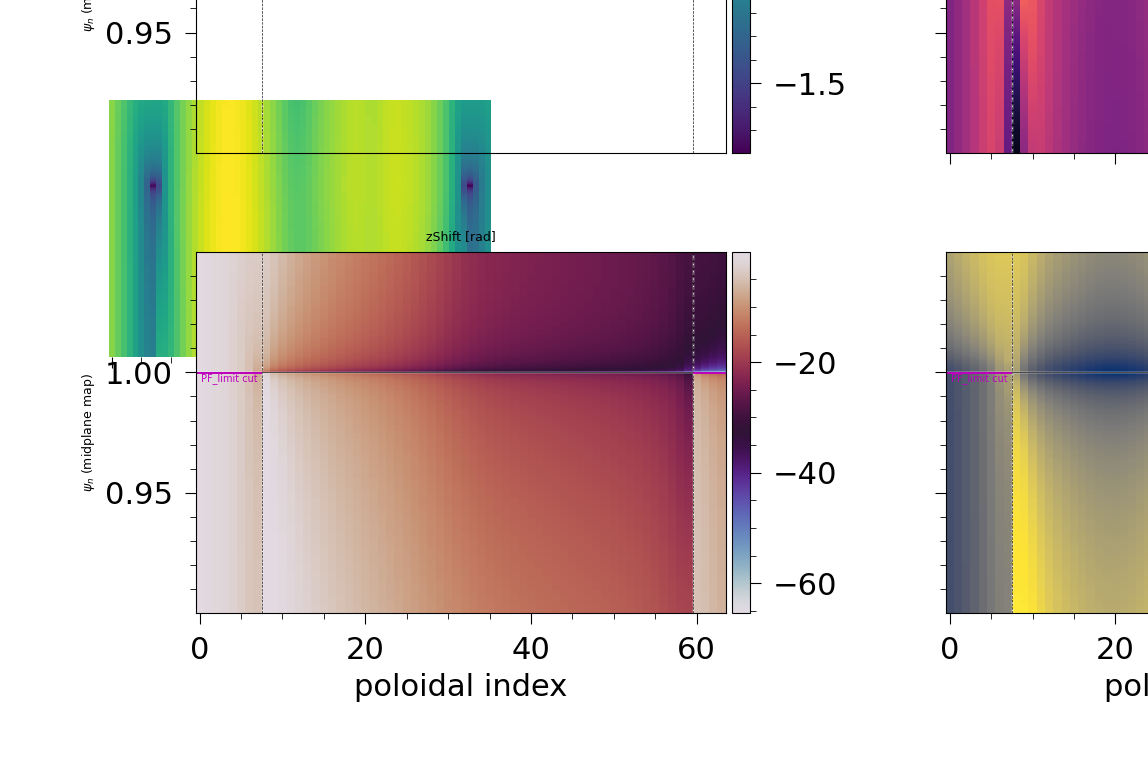


LOADING .npy from <no data_dir>

0  PROFILE SUMMARY (table)
  no profiles to summarise

2-D MAPS OF CRASH-RELEVANT FIELDS
  no Te/Ni fields loaded -- skipping 2-D maps

H1  SEPARATRIX DEFECTS (equilibrium kinks, one-cell spikes at ixsep)
  Niexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.51   <-- corner
  Teexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.21
  Tiexp   max radial kink K within ixsep-3..+2 (upstream rows) = 0.19
  Jpar0   max radial kink K within ixsep-3..+2 (upstream rows) = 0.08
  Teexp   radial    max K = 0.36 at ix=92 (psi_n~0.9930), j=8 [core]
  Teexp   poloidal  max K = 0.00 at ix=108 (psi_n~0.9967), j=4 [leg PF]
  Tiexp   radial    max K = 0.30 at ix=92 (psi_n~0.9930), j=8 [core]
  Tiexp   poloidal  max K = 0.00 at ix=103 (psi_n~0.9957), j=61 [leg PF]
  Niexp   radial    max K = 0.97 at ix=129 (psi_n~0.9999), j=7 [leg PF]
  Niexp   poloidal  max K = 0.00 at ix=112 (psi_n~0.9974), j=61 [leg PF]
  Jpar0   radial    max K = 2.13 at ix=6

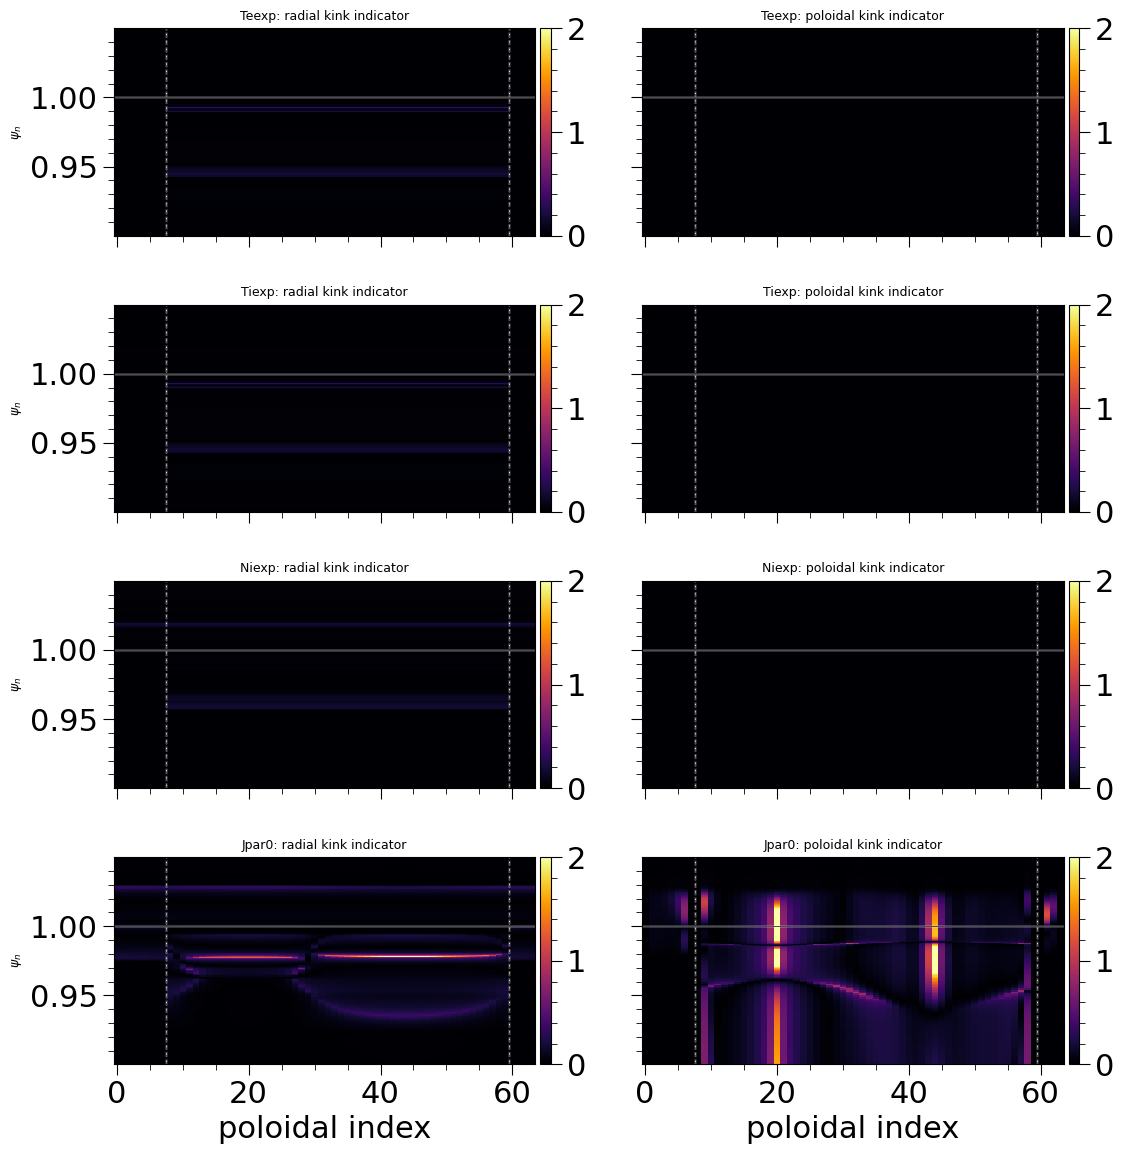

  leg rows: modal spike index ix=133 (psi_n 1.0005), 47% of samples; PF_limit cut at ix=128, separatrix at ix=130
  saved ./crash_diagnostics/spike_locator_Xe_t.png


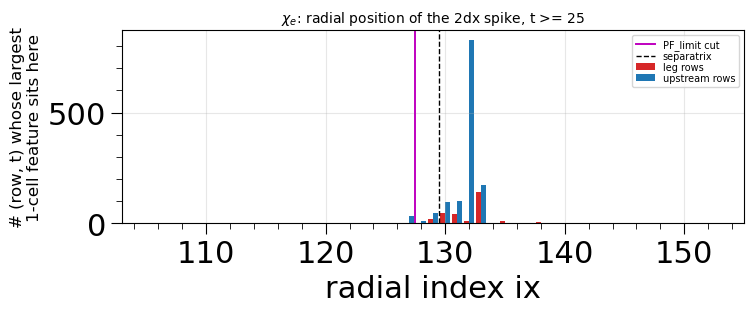

  upstream one-cell spikes within ixsep+-2: 84%

H2  PROFILE COLLAPSE / STIFFNESS
  floor_watch SKIPPED: no data_dir given (pass data_dir=<numpy dir> or run=<run dir>); 

H3  LEGS / SHEATH / PF

Da_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 1.73e-07   gamma +0.024
   SOL upstream   final 1.13e-07   gamma +0.023
   leg SOL        final 1.02e-07   gamma +0.023
   leg PF         final 1.67e-08   gamma +0.021

Xe_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 5.78e-08   gamma +0.023
   SOL upstream   final 4.18e-08   gamma +0.020
   leg SOL        final 1.22e-07   gamma +0.021
   leg PF         final 1.94e-10   gamma +0.000

Xi_t:  growth rate per region (last third of run, 1/tau_A)
   core           final 2.83e-08   gamma +0.020
   SOL upstream   final 9.04e-08   gamma +0.021
   leg SOL        final 6.63e-08   gamma +0.017
   leg PF         final 3.98e-08   gamma +0.022

location of max|Da_t| per output:
   t= 1  ix= 35

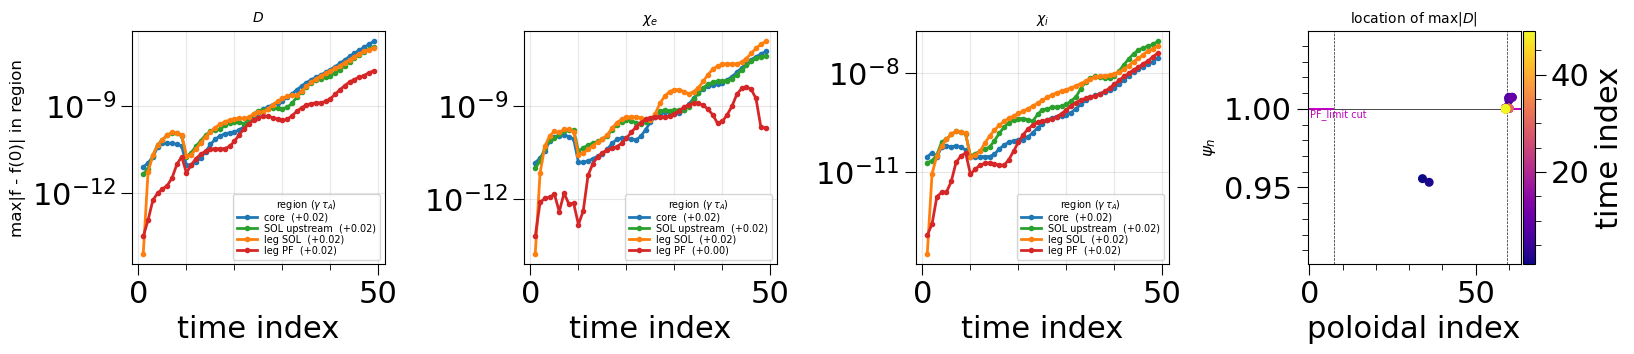

  saved ./crash_diagnostics/crash_map_Xe_t.png


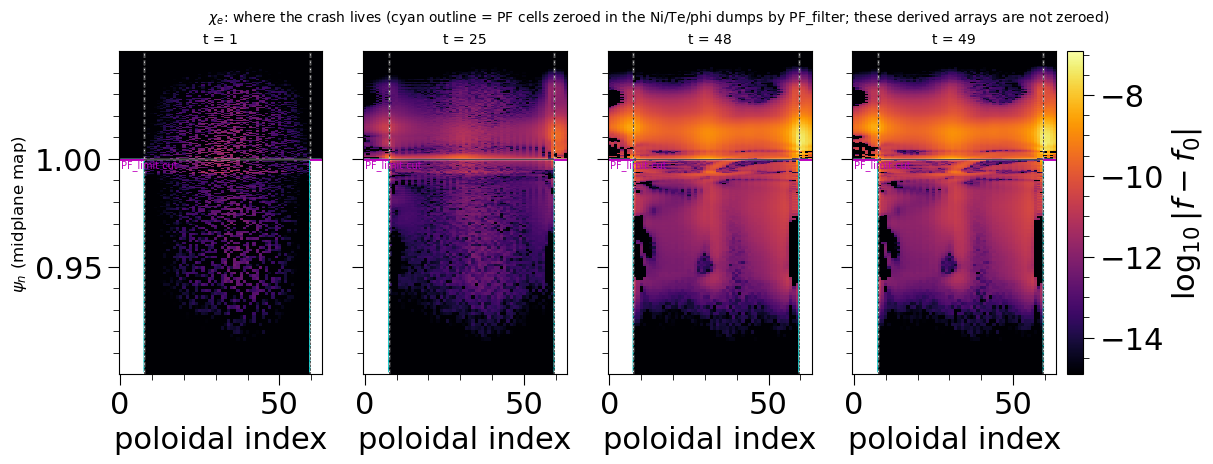

  last third: global max of Xe_t in leg rows 100% of outputs; in the leg PF band ix 125..129 (next to the separatrix) 0%
  leg / upstream amplitude at last output: 2.11e+00

H4  DRIVE (vorticity terms, needs output_transfer = true)
  no T_C/T_M/T_R/T_G .npy in None (needs output_transfer = true and bout_save_submit saving those variables)

VERDICT
  H1 separatrix        SUPPORTED  max kink K 0.51, 84% of upstream spikes at ixsep+-2
  H2a profile collapse n/a        no profiles
  H2b stiffness        n/a        no log
  H3 legs/sheath       SUPPORTED  max in legs 100% of late outputs (0% in leg PF band next to sep), leg/upstream 2.1e+00
  H4 drive             n/a        not available

All figures written to: /global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_kefit_jpar_solps_add/0_iteration/crash_diagnostics
report text written to /global/cfs/cdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_kefit_jpar_solps_add/0_iteration/crash_diagnostics/report.txt


({'nx': 260,
  'ny': 64,
  'ixsep': 130,
  'ixsep2': 260,
  'jyseps1_1': 7,
  'jyseps2_1': 32,
  'jyseps1_2': 32,
  'jyseps2_2': 59,
  'leg_y': array([ True,  True,  True,  True,  True,  True,  True,  True, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False,  True,  True,  True,
          True]),
  'pf': array([[ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True],
         ...,
         [False, False, False, ..., False, False, False],
         [False, False, False, ..., False, False, False],
         [False, False, Fa

In [6]:
import sibil_debug_diagnostics as dbg
display(dbg.make_debug_widget(convergent_transport_coeffs, psin_mid,
                              jomp=jomp, grid=grid, data_dir=data_dir))
dbg.full_report(convergent_transport_coeffs, psin_mid, grid_fname,
                jomp=jomp, savedir="./crash_diagnostics")